# Project 1: SNLI classification

**One experiment:** fit one shared **2,000-token BPE** on training + validation
text, compare nine fixed systems with grouped CV, select the highest mean CV
accuracy, refit that system on training + validation, and evaluate on test.
There is no hyperparameter search or validation-based early stopping.

All custom implementation is in this notebook. Tables stay in its outputs;
plots are also exported to `figures/project1_2k/` as PNG and PDF files.
There are no experiment logs, model checkpoints or local helper imports.
Run All performs fresh training and replaces the displayed outputs.

**Evaluation boundary:** the shared tokenizer sees CV held-out text, without
labels. These CV results are conditional on that shared tokenizer, not estimates
for an entirely fold-fitted preprocessing pipeline. The bigram inventory and
classifiers are still fitted on each fold's training rows. No test text is used
to learn the tokenizer, features or classifier. Exact test-premise overlaps are
removed from the development pool, as in our previous protocol.

Earlier work already evaluated a different model on test. This is a new
experiment, not an untouched first test evaluation; none of its settings is
selected using the new test scores.


## 1. Fixed configuration

The architectures and representations are the candidates; training settings
stay fixed. Three epochs are used in both CV and the final fit. The BPE vocabulary
and bigram inventory are each capped at **2,000 types**, giving up to **4,000
columns** for every pair representation. BPE types are individual tokens; bigram
types are ordered pairs of those tokens. Their caps are separate choices.


In [4]:
from array import array
from collections import Counter
from itertools import chain, combinations
from pathlib import Path
from time import perf_counter
import random
import warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import t
import torch
from torch import nn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from datasets import DatasetDict, disable_progress_bars, load_dataset, load_from_disk
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Metaspace
from tokenizers.trainers import BpeTrainer
from IPython.display import display

disable_progress_bars()
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "part1/project.ipynb").exists())
PART1 = ROOT / "part1"
FIGURES = PART1 / "figures/project1_2k"
LABELS = ["entailment", "neutral", "contradiction"]
REPRESENTATIONS = ["indicators", "unigram_counts", "bigram_counts"]
CLASSIFIERS = ["logistic", "mlp_one_hidden", "mlp_two_hidden"]

BASE = {
    "revision": "cdb5c3d5eed6ead6e5a341c8e56e669bb666725b",
    "vocab_size": 2000,
    "bpe_min_frequency": 2,
    "bigram_min_frequency": 2,
    "max_bigrams": 2000,
    "hidden_dims": {"mlp_one_hidden": [128], "mlp_two_hidden": [128, 64]},
    "dropout": 0.1,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 128,
    "epochs": 3,
    "logistic": {"solver": "saga", "C": 1.0, "max_iter": 1000, "tol": 0.0001},
    "cv_rows": 60000,
    "n_splits": 5,
    "cv_seeds": [0],
    "model_seed": 0,
    "sampling_seed": 0,
    "rope": 0.005,
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def save_figure(figure, name):
    FIGURES.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "pdf"):
        figure.savefig(FIGURES / f"{name}.{extension}", dpi=180, bbox_inches="tight")


set_seed(BASE["model_seed"])
torch.set_num_threads(1)
display(pd.DataFrame({"setting": list(BASE), "value": [str(value) for value in BASE.values()]}))


,setting,value
0,revision,cdb5c3d5eed6ead6e5a341c8e56e669bb666725b
1,vocab_size,2000
2,bpe_min_frequency,2
3,bigram_min_frequency,2
4,max_bigrams,2000
5,hidden_dims,"{'mlp_one_hidden': [128], 'mlp_two_hidden': [1..."
6,dropout,0.1
7,learning_rate,0.001
8,weight_decay,0.0001
9,batch_size,128


## 2. Data and CV partitions

SNLI has three labels: entailment, neutral and contradiction. Remove unlabelled
or blank pairs, combine the official training and validation splits, and exclude
exact premises present in test. Only test-premise membership is used here.
The classifier comparison uses a fixed approximately 60,000-row subset of
complete premise groups for runtime; the final fit uses the full eligible pool.


In [5]:
def load_snli(config=BASE):
    directory = PART1 / "data/snli" / config["revision"] / "cleaned-v1"
    if directory.exists():
        return load_from_disk(str(directory))

    raw = load_dataset(
        "stanfordnlp/snli",
        revision=config["revision"],
        cache_dir=str(PART1 / "data/huggingface"),
    )
    cleaned = {}
    for split, rows in raw.items():
        rows = rows.map(
            lambda row, index: {"example_id": f"{split}:{index}"},
            with_indices=True,
        )
        cleaned[split] = rows.filter(
            lambda row: row["label"] in (0, 1, 2)
            and all(isinstance(row[field], str) and row[field].strip()
                    for field in ("premise", "hypothesis"))
        )
    return DatasetDict(cleaned)


def development_pool(data):
    frames = []
    for split in ("train", "validation"):
        frame = data[split].select_columns(
            ["premise", "hypothesis", "label", "example_id"]
        ).to_pandas()
        frame["source_split"] = split
        frames.append(frame)

    combined = pd.concat(frames, ignore_index=True)
    test_premises = set(data["test"]["premise"])
    development = combined.loc[~combined.premise.isin(test_premises)].copy()
    development["premise_group"] = development.premise
    development = development.reset_index(drop=True)

    assert development.example_id.is_unique
    assert set(development.premise).isdisjoint(test_premises)
    assert set(development.source_split) <= {"train", "validation"}
    return development


def sample_groups(frame, target_rows, seed):
    if not 1 <= target_rows <= len(frame):
        raise ValueError("The sample target must lie within the development pool.")

    sizes = frame.groupby("premise_group", sort=True).size()
    shuffled = sizes.iloc[np.random.default_rng(seed).permutation(len(sizes))]
    count = np.searchsorted(shuffled.cumsum(), target_rows) + 1
    selected = frame.premise_group.isin(shuffled.index[:count])
    return frame.loc[selected].reset_index(drop=True)


def make_assignments(frame, config=BASE):
    assignments = frame[["premise_group", "label"]].copy()
    for seed in config["cv_seeds"]:
        splitter = StratifiedGroupKFold(
            n_splits=config["n_splits"], shuffle=True, random_state=seed
        )
        for fold, (_, heldout) in enumerate(
            splitter.split(frame, frame.label, frame.premise_group)
        ):
            assignments.loc[heldout, f"fold_seed_{seed}"] = fold
        assignments[f"fold_seed_{seed}"] = assignments[f"fold_seed_{seed}"].astype(int)
    return assignments


data = load_snli()
assert all(data[split].features["label"].names == LABELS for split in data)
development = development_pool(data)
cv_data = sample_groups(development, BASE["cv_rows"], BASE["sampling_seed"])
assignments = make_assignments(cv_data)

display(pd.DataFrame({"split": list(data), "clean_rows": [len(data[split]) for split in data]}))
display(pd.DataFrame({
    "pool": ["Full development / BPE / final fit", "CV subset"],
    "rows": [len(development), len(cv_data)],
    "premise_groups": [development.premise_group.nunique(), cv_data.premise_group.nunique()],
}))
display(pd.crosstab(development.source_split, development.label).rename(columns=dict(enumerate(LABELS))))


,split,clean_rows
0,train,549367
1,validation,9842
2,test,9824


,pool,rows,premise_groups
0,Full development / BPE / final fit,559164,154028
1,CV subset,60002,16512


label,entailment,neutral,contradiction
source_split,,,
train,183402,182751,183172
validation,3328,3234,3277


## 3. Shared BPE and feature representations

BPE is learned **once**, from both sentence roles in the full eligible
development pool. Its settings, vocabulary and token IDs stay unchanged through
CV and final fitting. Casing and punctuation are preserved; Metaspace handles
word boundaries. Test sentences are encoded only after model selection.

For each pair the input is `[premise features; hypothesis features]`.
Indicators record token presence, unigram counts record token frequency, and
pure bigram counts record retained adjacent BPE-token pairs. Bigrams never cross
sentence boundaries, and have no unigram fallback. Each CV fold learns its
bigram inventory from its training partition only.


In [6]:
def fit_tokenizer(training_text, config=BASE):
    tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
    tokenizer.pre_tokenizer = Metaspace(
        replacement="▁", prepend_scheme="always", split=True
    )
    trainer = BpeTrainer(
        vocab_size=config["vocab_size"],
        min_frequency=config["bpe_min_frequency"],
        special_tokens=["[UNK]"],
        show_progress=False,
    )
    texts = chain.from_iterable(zip(training_text.premise, training_text.hypothesis))
    tokenizer.train_from_iterator(texts, trainer=trainer, length=2 * len(training_text))
    return tokenizer


def encode_pairs(tokenizer, frame, batch_size=2048):
    roles = []
    for name in ("premise", "hypothesis"):
        ids, offsets = array("i"), array("q", [0])
        texts = frame[name].tolist()
        for start in range(0, len(texts), batch_size):
            encodings = tokenizer.encode_batch(texts[start:start + batch_size])
            for encoding in encodings:
                ids.extend(encoding.ids)
                offsets.append(len(ids))
        roles.append((np.asarray(ids, dtype=np.int32), np.asarray(offsets, dtype=np.int64)))
    return roles


def learn_bigrams(tokens, config=BASE):
    counts = Counter()
    for ids, offsets in tokens:
        for start, end in zip(offsets[:-1], offsets[1:]):
            sentence = ids[start:end].tolist()
            counts.update(zip(sentence, sentence[1:]))
    ranked = sorted(counts.items(), key=lambda item: (-item[1], item[0]))
    retained = [pair for pair, count in ranked if count >= config["bigram_min_frequency"]]
    return retained[:config["max_bigrams"]]


class PairEncoder:
    def __init__(self, tokenizer, bigrams):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()
        self.bigrams = bigrams


In [7]:
def feature_matrix(encoder, tokens, representation):
    """Construct sparse premise/hypothesis blocks without cross-sentence bigrams."""
    width = encoder.vocab_size
    inventory = np.array([a * width + b for a, b in encoder.bigrams], dtype=np.int64)
    permutation = np.argsort(inventory)
    sorted_pairs = inventory[permutation]
    blocks = []
    for ids, offsets in tokens:
        n_rows = len(offsets) - 1
        if representation in ("indicators", "unigram_counts"):
            rows = np.repeat(np.arange(n_rows), np.diff(offsets))
            block = sparse.csr_matrix((np.ones(len(ids), np.float32), (rows, ids)), shape=(n_rows, width))
            if representation == "indicators":
                block.data.fill(1)
        elif representation == "bigram_counts":
            valid = np.ones(max(0, len(ids) - 1), dtype=bool)
            boundaries = offsets[1:-1] - 1
            valid[boundaries[(boundaries >= 0) & (boundaries < len(valid))]] = False
            positions = np.flatnonzero(valid)
            pairs = ids[positions].astype(np.int64) * width + ids[positions + 1]
            locations = np.searchsorted(sorted_pairs, pairs)
            keep = locations < len(sorted_pairs)
            if len(sorted_pairs):
                keep[keep] &= sorted_pairs[locations[keep]] == pairs[keep]
            rows = np.searchsorted(offsets[1:], positions[keep], side="right")
            block = sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, permutation[locations[keep]])),
                                      shape=(n_rows, len(inventory)))
        else:
            raise ValueError(f"Unknown representation: {representation}")
        blocks.append(block)
    return sparse.hstack(blocks, format="csr", dtype=np.float32)


In [8]:
bpe_started = perf_counter()
tokenizer = fit_tokenizer(development[["premise", "hypothesis"]])
tokenizer_snapshot = tokenizer.to_str()
bpe_seconds = perf_counter() - bpe_started

display(pd.DataFrame([{
    "BPE training rows": len(development),
    "target vocabulary": BASE["vocab_size"],
    "actual vocabulary": tokenizer.get_vocab_size(),
    "test rows used": 0,
    "seconds": bpe_seconds,
}]))


,BPE training rows,target vocabulary,actual vocabulary,test rows used,seconds
0,559164,2000,2000,0,2.256986


## 4. Classifiers and fixed training loop

Logistic regression uses a multinomial softmax with L2 regularization. The MLPs
use a sparse first layer, ReLU, dropout and one or two hidden layers. Their output
is log-softmax; `NLLLoss` matches that output. AdamW applies decoupled weight decay.
Each neural fit takes exactly three epochs, without accessing held-out labels.


In [9]:
def score(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    assert probabilities.shape == (len(labels), 3) and len(labels) > 0
    assert np.isfinite(probabilities).all() and (probabilities >= 0).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    predictions = probabilities.argmax(axis=1)
    gold_probabilities = probabilities[np.arange(len(labels)), labels]
    return {
        "accuracy": accuracy_score(labels, predictions),
        "nll": -np.log(np.clip(gold_probabilities, np.finfo(float).eps, 1)).mean(),
        "macro_f1": f1_score(
            labels, predictions, labels=[0, 1, 2], average="macro", zero_division=0
        ),
    }


def sparse_tensor(matrix):
    coo = matrix.tocoo()
    indices = torch.from_numpy(np.vstack((coo.row, coo.col)).astype(np.int64))
    values = torch.from_numpy(np.asarray(coo.data, dtype=np.float32))
    return torch.sparse_coo_tensor(indices, values, coo.shape, check_invariants=True).coalesce()


class PairMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(input_dim, hidden_dims[0]))
        self.bias = nn.Parameter(torch.zeros(hidden_dims[0]))
        nn.init.xavier_uniform_(self.weight)
        layers = [nn.ReLU(), nn.Dropout(dropout)]
        for before, after in zip(hidden_dims, hidden_dims[1:]):
            layers.extend([nn.Linear(before, after), nn.ReLU(), nn.Dropout(dropout)])
        layers.extend([nn.Linear(hidden_dims[-1], 3), nn.LogSoftmax(dim=-1)])
        self.output = nn.Sequential(*layers)

    def forward(self, features):
        hidden = torch.sparse.mm(features, self.weight) + self.bias
        return self.output(hidden)


def predict_proba(fitted, features, batch_size=1024):
    model = fitted["model"]
    if fitted["classifier"] == "logistic":
        assert np.array_equal(model.classes_, [0, 1, 2])
        return model.predict_proba(features)

    model.eval()
    probabilities = []
    with torch.no_grad():
        for start in range(0, features.shape[0], batch_size):
            batch = sparse_tensor(features[start:start + batch_size])
            probabilities.append(model(batch).exp().numpy())
    return np.concatenate(probabilities)


In [10]:
def fit_model(features, labels, classifier, config=BASE):
    labels = np.asarray(labels, dtype=np.int64)
    assert features.shape[0] == len(labels) and set(labels) == {0, 1, 2}
    set_seed(config["model_seed"])

    if classifier == "logistic":
        model = LogisticRegression(
            **config["logistic"], l1_ratio=0.0, random_state=config["model_seed"]
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(features, labels)
        converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught)
        return {"classifier": classifier, "model": model, "history": [], "converged": converged}

    model = PairMLP(
        features.shape[1], config["hidden_dims"][classifier], config["dropout"]
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    criterion = nn.NLLLoss()
    random_order = np.random.default_rng(config["model_seed"])
    history = []

    for epoch in range(config["epochs"]):
        model.train()
        order = random_order.permutation(len(labels))
        total_loss, correct = 0.0, 0

        for start in range(0, len(labels), config["batch_size"]):
            indices = order[start:start + config["batch_size"]]
            batch = sparse_tensor(features[indices])
            target = torch.as_tensor(labels[indices], dtype=torch.long)

            optimizer.zero_grad(set_to_none=True)
            log_probabilities = model(batch)
            loss = criterion(log_probabilities, target)
            assert torch.isfinite(loss)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(indices)
            correct += (log_probabilities.argmax(dim=1) == target).sum().item()

        history.append({
            "epoch": epoch + 1,
            "training_nll_online": total_loss / len(labels),
            "training_accuracy_online": correct / len(labels),
        })

    model.eval()
    return {"classifier": classifier, "model": model, "history": history, "converged": True}


## 5. Cross-validation and model selection

All nine systems use the same premise-grouped partitions. Fold validation labels
are used only to calculate metrics after training. Select the highest **mean CV
accuracy**, with lower mean NLL breaking an exact tie. Accuracy and macro-F1 are
fractions; NLL uses natural logarithms. The standard deviation describes the
spread of dependent fold scores, not an independent-sample standard error.
One complete five-fold repetition (45 fits) keeps this run affordable. Compared
with the earlier three-repetition experiment, Bayesian uncertainty is wider.


In [11]:
def run_cv(data, assignments, tokenizer, config=BASE):
    results = []
    predictions = []

    for seed in config["cv_seeds"]:
        for fold in range(config["n_splits"]):
            heldout = assignments[f"fold_seed_{seed}"].eq(fold)
            training = data.loc[~heldout]
            validation = data.loc[heldout]

            assert set(training.premise_group).isdisjoint(validation.premise_group)

            # BPE is already fixed; only the bigram inventory is learned here.
            train_tokens = encode_pairs(tokenizer, training)
            val_tokens = encode_pairs(tokenizer, validation)
            encoder = PairEncoder(tokenizer, learn_bigrams(train_tokens, config))
            started = perf_counter()

            for representation in REPRESENTATIONS:
                train_features = feature_matrix(encoder, train_tokens, representation)
                val_features = feature_matrix(encoder, val_tokens, representation)

                for classifier in CLASSIFIERS:
                    model = fit_model(train_features, training.label, classifier, config)
                    probabilities = predict_proba(model, val_features)

                    results.append({
                        "seed": seed,
                        "fold": fold,
                        "representation": representation,
                        "classifier": classifier,
                        "converged": model["converged"],
                        **score(validation.label, probabilities),
                    })

                    # Retain one OOF repetition for error analysis, in memory only.
                    if seed == config["cv_seeds"][0]:
                        prediction = pd.DataFrame(probabilities, columns=["p0", "p1", "p2"])
                        prediction["row"] = validation.index.to_numpy()
                        prediction["representation"] = representation
                        prediction["classifier"] = classifier
                        predictions.append(prediction)

            print(f"Seed {seed}, fold {fold + 1}/{config['n_splits']} complete "
                  f"({perf_counter() - started:.1f} seconds)", flush=True)

    return pd.DataFrame(results), pd.concat(predictions, ignore_index=True)


def summarise_cv(results):
    return results.groupby(["representation", "classifier"], as_index=False).agg(
        cv_accuracy=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        cv_nll=("nll", "mean"),
        cv_macro_f1=("macro_f1", "mean"),
        folds=("fold", "size"),
        converged=("converged", "all"),
    ).sort_values(
        ["cv_accuracy", "cv_nll", "representation", "classifier"],
        ascending=[False, True, True, True],
    ).reset_index(drop=True)


In [12]:
cv_started = perf_counter()
cv_results, oof_predictions = run_cv(cv_data, assignments, tokenizer)
cv_seconds = perf_counter() - cv_started
assert tokenizer.to_str() == tokenizer_snapshot
assert len(cv_results) == len(BASE["cv_seeds"]) * BASE["n_splits"] * 9
assert not cv_results.duplicated(["seed", "fold", "representation", "classifier"]).any()

cv_summary = summarise_cv(cv_results)
display(cv_summary.style.format({
    "cv_accuracy": "{:.2%}", "accuracy_std": "{:.2%}",
    "cv_nll": "{:.4f}", "cv_macro_f1": "{:.4f}",
}))
winner = cv_summary.iloc[0]
print(f"Selected: {winner.representation} + {winner.classifier}; "
      f"mean CV accuracy {winner.cv_accuracy:.2%}")
print(f"CV elapsed: {cv_seconds / 60:.2f} minutes")


Seed 0, fold 1/5 complete (41.7 seconds)
Seed 0, fold 2/5 complete (42.0 seconds)
Seed 0, fold 3/5 complete (41.1 seconds)
Seed 0, fold 4/5 complete (38.7 seconds)
Seed 0, fold 5/5 complete (41.7 seconds)


,representation,classifier,cv_accuracy,accuracy_std,cv_nll,cv_macro_f1,folds,converged
0,indicators,mlp_two_hidden,62.60%,0.63%,0.8394,0.6245,5,True
1,unigram_counts,mlp_two_hidden,62.59%,0.79%,0.8408,0.6243,5,True
2,unigram_counts,mlp_one_hidden,61.95%,0.68%,0.8459,0.6183,5,True
3,indicators,mlp_one_hidden,61.92%,0.49%,0.8457,0.6179,5,True
4,indicators,logistic,60.52%,0.51%,0.8965,0.6043,5,True
5,unigram_counts,logistic,60.41%,0.52%,0.8965,0.6032,5,True
6,bigram_counts,mlp_one_hidden,53.78%,0.25%,0.9499,0.5367,5,True
7,bigram_counts,mlp_two_hidden,53.66%,0.33%,0.9533,0.5338,5,True
8,bigram_counts,logistic,52.75%,0.31%,0.9778,0.5265,5,True


Selected: indicators + mlp_two_hidden; mean CV accuracy 62.60%
CV elapsed: 3.51 minutes


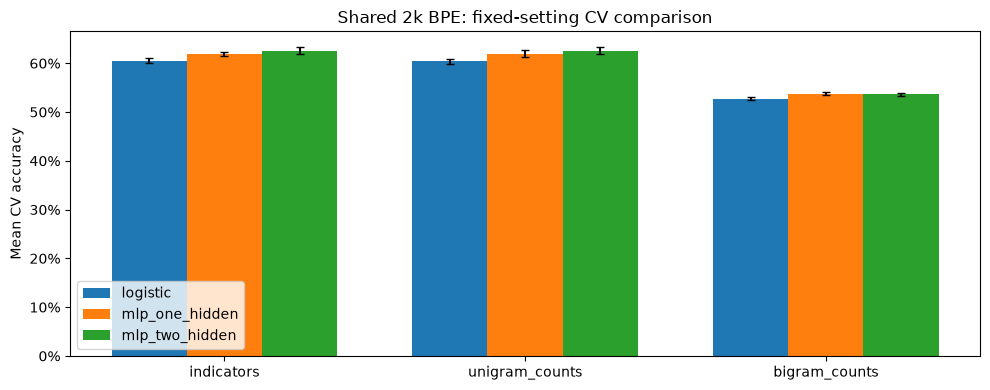

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(REPRESENTATIONS))
for offset, classifier in enumerate(CLASSIFIERS):
    rows = cv_summary.loc[cv_summary.classifier.eq(classifier)].set_index("representation")
    rows = rows.loc[REPRESENTATIONS]
    ax.bar(positions + (offset - 1) * 0.25, rows.cv_accuracy, width=0.25,
           yerr=rows.accuracy_std, capsize=3, label=classifier)
ax.set(xticks=positions, xticklabels=REPRESENTATIONS,
       ylabel="Mean CV accuracy", title="Shared 2k BPE: fixed-setting CV comparison")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
save_figure(fig, "cv_accuracy")
plt.show()


## 6. Bayesian comparisons and ROPE sensitivity

Compare matched fold accuracies with the tutorial's Bayesian correlated-t model.
The posterior for the difference **B − A** uses the sample variance multiplied by
`1 / number_of_scores + 1 / (number_of_folds - 1)`. This accounts approximately
for dependence from overlapping training folds. It remains conditional on the
shared tokenizer, fixed subset, settings and split repetitions.

The primary ROPE is ±0.005 accuracy (±0.5 percentage points): differences that
small do not justify a strong practical claim for this project. This is a project
judgement. Also show ±0.25 and ±1 percentage point sensitivity. These comparisons
describe uncertainty; they do not change the accuracy-based selection rule.


In [14]:
def correlated_posterior(a, b, n_splits=5, rope=0.005):
    difference = np.asarray(b, dtype=float) - np.asarray(a, dtype=float)
    count = len(difference)
    assert count >= 4 and count % n_splits == 0
    mean = difference.mean()
    scale = np.sqrt(difference.var(ddof=1) * (1 / count + 1 / (n_splits - 1)))

    if scale == 0:
        left, right = float(mean < -rope), float(mean > rope)
        low, high = mean, mean
        equivalent = 1 - left - right
    else:
        posterior = t(df=count - 1, loc=mean, scale=scale)
        left, right = posterior.cdf(-rope), posterior.sf(rope)
        equivalent = posterior.cdf(rope) - posterior.cdf(-rope)
        low, high = posterior.interval(0.95)

    return {
        "difference_B_minus_A": mean,
        "ci_low": low,
        "ci_high": high,
        "student_scale": scale,
        "degrees_of_freedom": count - 1,
        "P_A_better": left,
        "P_equivalent": equivalent,
        "P_B_better": right,
    }


def bayesian_comparisons(results, rope, config=BASE):
    paired = results.pivot(
        index=["seed", "fold"], columns=["representation", "classifier"], values="accuracy"
    ).sort_index()
    assert not paired.isna().any().any()
    rows = []
    systems = list(paired.columns)
    for a, b in combinations(systems, 2):
        if (a[0] == b[0]) == (a[1] == b[1]):
            continue  # Compare one changed factor at a time.
        posterior = correlated_posterior(paired[a], paired[b], config["n_splits"], rope)
        rows.append({"A": " / ".join(a), "B": " / ".join(b), **posterior})
    return pd.DataFrame(rows)


posteriors = bayesian_comparisons(cv_results, BASE["rope"])
display(posteriors.drop(columns=["student_scale", "degrees_of_freedom"]).style.format({
    "difference_B_minus_A": "{:+.2%}", "ci_low": "{:+.2%}", "ci_high": "{:+.2%}",
    "P_A_better": "{:.2%}", "P_equivalent": "{:.2%}", "P_B_better": "{:.2%}",
}))

sensitivity_rows = []
for width in [0.0025, 0.005, 0.01]:
    comparison = bayesian_comparisons(cv_results, width)
    comparison["ROPE half-width (pp)"] = width * 100
    sensitivity_rows.append(comparison)
sensitivity = pd.concat(sensitivity_rows, ignore_index=True)
display(sensitivity.pivot(
    index=["A", "B"], columns="ROPE half-width (pp)", values="P_equivalent"
).style.format("{:.2%}"))


,A,B,difference_B_minus_A,ci_low,ci_high,P_A_better,P_equivalent,P_B_better
0,indicators / logistic,indicators / mlp_one_hidden,+1.39%,+1.12%,+1.67%,0.00%,0.04%,99.96%
1,indicators / logistic,indicators / mlp_two_hidden,+2.08%,+1.69%,+2.47%,0.00%,0.01%,99.98%
2,indicators / logistic,unigram_counts / logistic,-0.11%,-0.48%,+0.26%,2.18%,97.29%,0.53%
3,indicators / logistic,bigram_counts / logistic,-7.78%,-8.69%,-6.86%,100.00%,0.00%,0.00%
4,indicators / mlp_one_hidden,indicators / mlp_two_hidden,+0.69%,+0.22%,+1.16%,0.11%,16.43%,83.46%
5,indicators / mlp_one_hidden,unigram_counts / mlp_one_hidden,+0.04%,-0.33%,+0.41%,0.77%,97.95%,1.27%
6,indicators / mlp_one_hidden,bigram_counts / mlp_one_hidden,-8.13%,-9.34%,-6.92%,100.00%,0.00%,0.00%
7,indicators / mlp_two_hidden,unigram_counts / mlp_two_hidden,-0.01%,-0.40%,+0.37%,1.22%,97.75%,1.03%
8,indicators / mlp_two_hidden,bigram_counts / mlp_two_hidden,-8.95%,-10.01%,-7.88%,100.00%,0.00%,0.00%
9,unigram_counts / logistic,unigram_counts / mlp_one_hidden,+1.54%,+0.87%,+2.21%,0.05%,0.57%,99.38%


## 7. Held-out CV errors

Use one OOF repetition only, so each development example appears once for the
selected system. These errors are diagnostic; no settings are changed afterwards.
The displayed examples are the first errors in a fixed row order, not a random
sample for estimating linguistic error-category frequencies.


In [15]:
chosen_oof = oof_predictions.loc[
    oof_predictions.representation.eq(winner.representation)
    & oof_predictions.classifier.eq(winner.classifier)
].sort_values("row")
assert chosen_oof.row.is_unique
assert np.array_equal(chosen_oof.row, np.arange(len(cv_data)))
oof_probabilities = chosen_oof[["p0", "p1", "p2"]].to_numpy()
oof_decisions = oof_probabilities.argmax(axis=1)

display(pd.DataFrame([{"evaluation": "Selected system: first OOF repetition",
                       **score(cv_data.label, oof_probabilities)}]))
errors = cv_data.loc[oof_decisions != cv_data.label.to_numpy(),
                     ["example_id", "premise", "hypothesis", "label"]].copy()
errors["prediction"] = oof_decisions[oof_decisions != cv_data.label.to_numpy()]
errors["label"] = errors.label.map(dict(enumerate(LABELS)))
errors["prediction"] = errors.prediction.map(dict(enumerate(LABELS)))
with pd.option_context("display.max_colwidth", 140):
    display(errors.head(12))


,evaluation,accuracy,nll,macro_f1
0,Selected system: first OOF repetition,0.626046,0.839428,0.624562


,example_id,premise,hypothesis,label,prediction
8,train:56,A woman in a green jacket and hood over her head looking towards a valley.,The woman is wearing green.,entailment,contradiction
9,train:132,"A man wearing black with a gray hat, holding a pitchfork, directs a horse-drawn cart.",The farmer wearing a gray hat is driving a horse-drawn cart.,neutral,contradiction
10,train:133,"A man wearing black with a gray hat, holding a pitchfork, directs a horse-drawn cart.",The man with the gray hat and pitchfork is directing the cart.,entailment,neutral
13,train:148,A dog drops a red disc on a beach.,a dog drops a disc with a boy,neutral,entailment
14,train:149,A dog drops a red disc on a beach.,a dog drops a red disc,entailment,neutral
16,train:292,A foreign family is walking along a dirt path next to the water.,People are walking next to a lake.,neutral,entailment
19,train:295,A foreign family is walking along a dirt path next to the water.,The family is admiring the water,entailment,neutral
22,train:298,A foreign family is walking along a dirt path next to the water.,they are trying not to fall in the water,neutral,contradiction
24,train:300,A foreign family is walking along a dirt path next to the water.,A family of foreigners walks by the water.,entailment,neutral
35,train:455,A woman in capri jeans crouches on the edge of a fountain with her left foot kicked out to touch the falling water.,A woman is like to touch the water in fountain,entailment,neutral


## 8. Final refit and test

Freeze the selected representation and architecture before evaluating test.
Keep the exact shared BPE and fixed hyperparameters, including three neural
epochs. Relearn the bigram inventory on the full development pool, then fit a
fresh classifier on all its labels. Test labels enter only the scoring/report
cells below. This test result belongs to this newly selected system; historical
test scores from other models are not substituted here.


In [16]:
final_started = perf_counter()
final_representation = str(winner.representation)
final_classifier = str(winner.classifier)

development_tokens = encode_pairs(tokenizer, development)
final_encoder = PairEncoder(tokenizer, learn_bigrams(development_tokens))
final_features = feature_matrix(final_encoder, development_tokens, final_representation)
del development_tokens

final_model = fit_model(final_features, development.label, final_classifier)
final_seconds = perf_counter() - final_started
assert tokenizer.to_str() == tokenizer_snapshot

display(pd.DataFrame([{
    "representation": final_representation,
    "classifier": final_classifier,
    "training_rows": len(development),
    "input_dimensions": final_features.shape[1],
    "BPE vocabulary": tokenizer.get_vocab_size(),
    "epochs": BASE["epochs"] if final_classifier != "logistic" else "solver convergence",
    "converged": final_model["converged"],
    "seconds": final_seconds,
}]))
del final_features


,representation,classifier,training_rows,input_dimensions,BPE vocabulary,epochs,converged,seconds
0,indicators,mlp_two_hidden,559164,4000,2000,3,True,60.304317


In [17]:
testing = data["test"].select_columns(["premise", "hypothesis", "label", "example_id"]).to_pandas()
test_tokens = encode_pairs(tokenizer, testing)
test_features = feature_matrix(final_encoder, test_tokens, final_representation)
test_probabilities = predict_proba(final_model, test_features)
test_decisions = test_probabilities.argmax(axis=1)
test_metrics = score(testing.label, test_probabilities)
del test_tokens, test_features
assert tokenizer.to_str() == tokenizer_snapshot

display(pd.DataFrame([{
    "evaluation": "Official test", "representation": final_representation,
    "classifier": final_classifier, "rows": len(testing), **test_metrics,
}]).style.format({"accuracy": "{:.2%}", "nll": "{:.4f}", "macro_f1": "{:.4f}"}))

class_report = pd.DataFrame(classification_report(
    testing.label, test_decisions, labels=[0, 1, 2], target_names=LABELS,
    output_dict=True, zero_division=0,
)).T
display(class_report.loc[LABELS].round(4))


,evaluation,representation,classifier,rows,accuracy,nll,macro_f1
0,Official test,indicators,mlp_two_hidden,9824,74.48%,0.6210,0.7439


,precision,recall,f1-score,support
entailment,0.7492,0.8168,0.7815,3368.0
neutral,0.6920,0.7015,0.6967,3219.0
contradiction,0.7989,0.7130,0.7535,3237.0


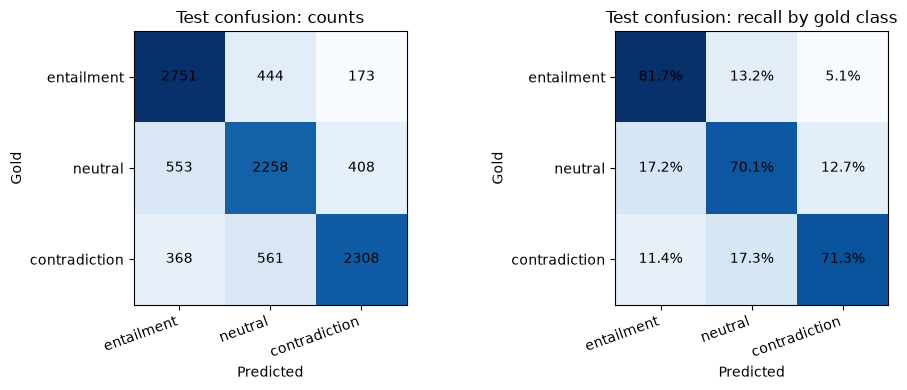

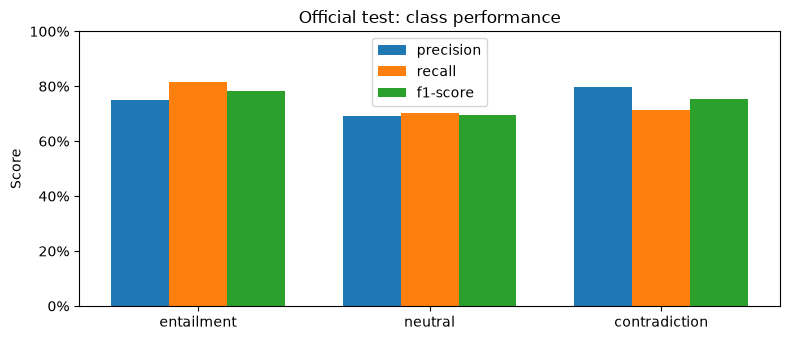

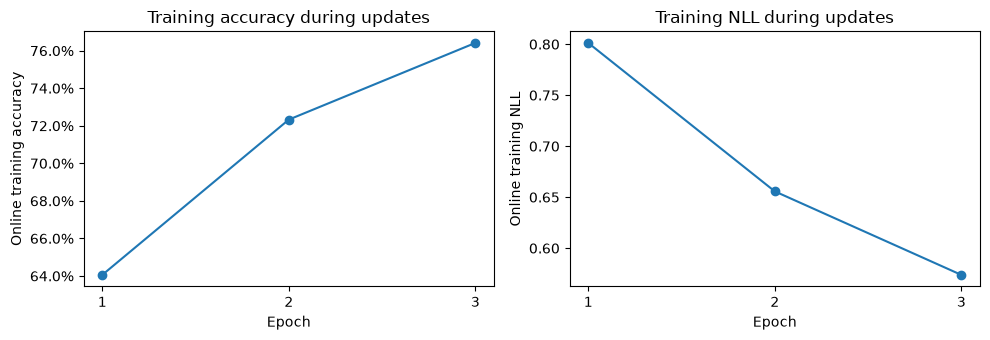

,premise,hypothesis,label,prediction
0,This church choir sings to the masses as they sing joyous songs from the book at a church.,The church has cracks in the ceiling.,neutral,entailment
1,This church choir sings to the masses as they sing joyous songs from the book at a church.,The church is filled with song.,entailment,neutral
2,This church choir sings to the masses as they sing joyous songs from the book at a church.,A choir singing at a baseball game.,contradiction,entailment
3,"A woman with a green headscarf, blue shirt and a very big grin.",The woman is young.,neutral,entailment
4,"A woman with a green headscarf, blue shirt and a very big grin.",The woman is very happy.,entailment,neutral
5,"A woman with a green headscarf, blue shirt and a very big grin.",The woman has been shot.,contradiction,entailment
12,A land rover is being driven across a river.,A Land Rover is splashing water as it crosses a river.,entailment,neutral
14,A land rover is being driven across a river.,A sedan is stuck in the middle of a river.,contradiction,neutral
36,Three firefighter come out of subway station.,Three firefighters putting out a fire inside of a subway station.,neutral,entailment
41,"A person wearing a straw hat, standing outside working a steel apparatus with a pile of coconuts on the ground.",A person is burning a straw hat.,contradiction,neutral


In [18]:
confusion = confusion_matrix(testing.label, test_decisions, labels=[0, 1, 2])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title in zip(
    axes, [confusion, confusion / confusion.sum(axis=1, keepdims=True)],
    ["Test confusion: counts", "Test confusion: recall by gold class"],
):
    image = ax.imshow(values, cmap="Blues")
    for row in range(3):
        for column in range(3):
            label = str(int(values[row, column])) if title.endswith("counts") else f"{values[row, column]:.1%}"
            ax.text(column, row, label, ha="center", va="center")
    ax.set(xticks=range(3), xticklabels=LABELS, yticks=range(3), yticklabels=LABELS,
           xlabel="Predicted", ylabel="Gold", title=title)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
save_figure(fig, "test_confusion")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(LABELS))
for offset, metric in enumerate(["precision", "recall", "f1-score"]):
    ax.bar(positions + (offset - 1) * 0.25, class_report.loc[LABELS, metric],
           width=0.25, label=metric)
ax.set(xticks=positions, xticklabels=LABELS, ylim=(0, 1),
       ylabel="Score", title="Official test: class performance")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
save_figure(fig, "test_class_metrics")
plt.show()

history = pd.DataFrame(final_model["history"])
if not history.empty:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.epoch, history.training_accuracy_online, marker="o")
    axes[0].set(title="Training accuracy during updates", ylabel="Online training accuracy",
                xlabel="Epoch", xticks=history.epoch)
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].plot(history.epoch, history.training_nll_online, marker="o")
    axes[1].set(title="Training NLL during updates", ylabel="Online training NLL",
                xlabel="Epoch", xticks=history.epoch)
    fig.tight_layout()
    save_figure(fig, "training_curves")
    plt.show()

test_errors = testing.loc[test_decisions != testing.label.to_numpy()].copy()
test_errors["prediction"] = test_decisions[test_decisions != testing.label.to_numpy()]
test_errors["label"] = test_errors.label.map(dict(enumerate(LABELS)))
test_errors["prediction"] = test_errors.prediction.map(dict(enumerate(LABELS)))
with pd.option_context("display.max_colwidth", 140):
    display(test_errors[["premise", "hypothesis", "label", "prediction"]].head(12))


The training curves measure minibatches **during updates**, with dropout active.
They are neither held-out accuracy nor the final model evaluated on the whole
training pool. Compare model generalization using the explicitly labelled CV
and official-test tables.

CV trains on a subset and final fitting uses the full development pool, so their
scores differ in both training size and evaluation examples. The best CV score
is also affected by selecting among nine candidates. These results do not measure
an isolated vocabulary-size improvement over earlier experiments. The shared
tokenizer, subset and fixed three-epoch schedule limit the conclusions.

The separate sentence-role blocks preserve which sentence a token came from,
but counts omit most ordering and sentence interactions. BPE bigrams capture
only retained local adjacencies. Negation scope, argument roles, paraphrase and
commonsense remain useful questions when reviewing the displayed errors.


## 9. Tutorial-style result plots

The tutorial's final analysis sections show **boxplots with individual fold
scores** and **posterior mean-difference curves with a shaded ROPE**. The plots
below use the actual five matched CV scores. Boxes describe fold variation;
their points are dependent, not five independent experiments.

The posterior panels change one factor at a time. Positive differences favour
B; negative differences favour A. The shaded interval is the primary ±0.5 pp
ROPE. The curve uses the Student-t **scale**, consistently with the probability
table above; its scale is not its standard deviation. Intervals are 95% posterior
credible intervals. The sensitivity heatmap changes the practical tolerance,
while keeping the observed scores and posterior distribution unchanged.

All figures are displayed here and exported as PNG/PDF to
`figures/project1_2k/` for use in the report or oral assessment.


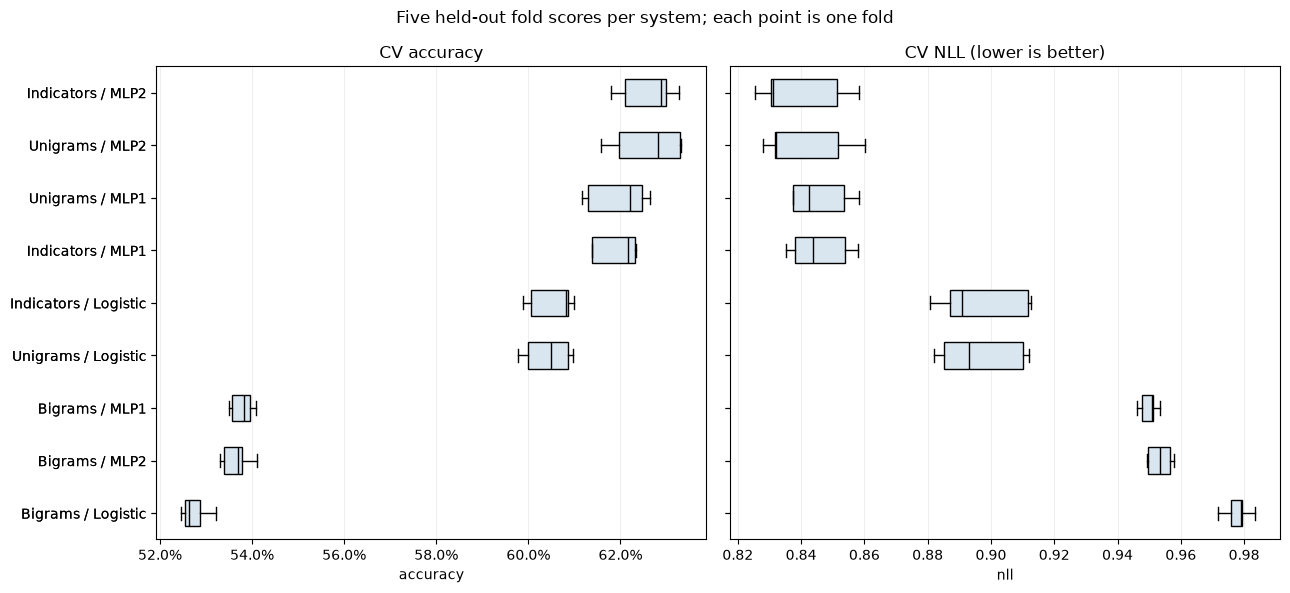

In [23]:
def system_name(system):
    representation, classifier = system
    representations = {"indicators": "Indicators", "unigram_counts": "Unigrams",
                       "bigram_counts": "Bigrams"}
    classifiers = {"logistic": "Logistic", "mlp_one_hidden": "MLP1", "mlp_two_hidden": "MLP2"}
    return f"{representations[representation]} / {classifiers[classifier]}"


systems = list(cv_summary[["representation", "classifier"]].itertuples(index=False, name=None))
labels = [system_name(system) for system in systems]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, metric, title in zip(axes, ["accuracy", "nll"], ["CV accuracy", "CV NLL (lower is better)"]):
    measurements = [cv_results.loc[
        cv_results.representation.eq(representation) & cv_results.classifier.eq(classifier), metric
    ].to_numpy() for representation, classifier in systems]
    ax.boxplot(measurements, orientation="horizontal", tick_labels=labels,
               showfliers=False, patch_artist=True,
               boxprops={"facecolor": "#d9e6ef"}, medianprops={"color": "black"})

    ax.set(title=title, xlabel=metric)
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle("Five held-out fold scores per system; each point is one fold")
fig.tight_layout()
save_figure(fig, "cv_boxplots_and_points")
plt.show()


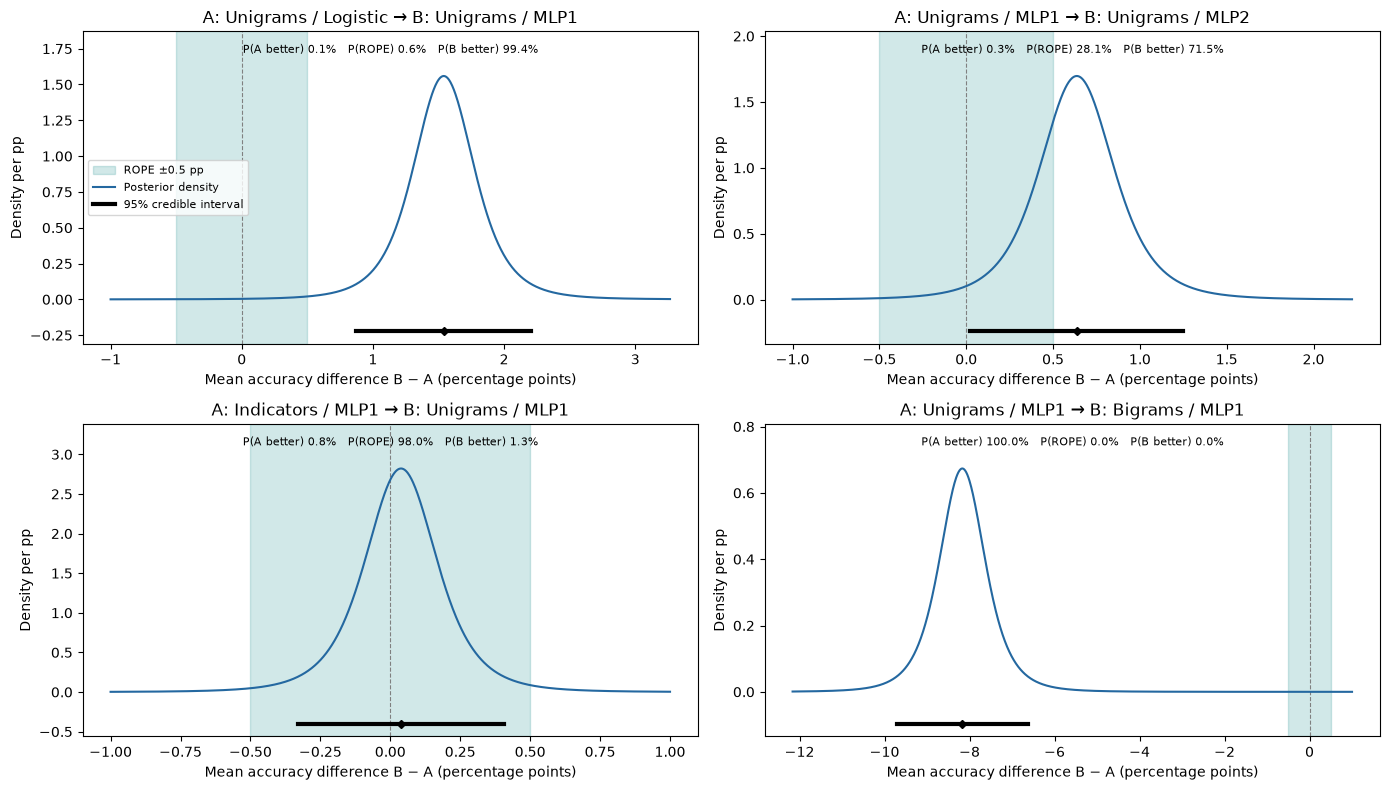

In [20]:
def plot_posterior(ax, scores_a, scores_b, name_a, name_b, config=BASE):
    result = correlated_posterior(scores_a, scores_b, config["n_splits"], config["rope"])
    rope_pp = 100 * config["rope"]
    mean_pp = 100 * result["difference_B_minus_A"]
    scale_pp = 100 * result["student_scale"]
    ax.axvspan(-rope_pp, rope_pp, color="teal", alpha=0.18, label="ROPE ±0.5 pp")
    ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
    if scale_pp > 0:
        posterior = t(df=result["degrees_of_freedom"], loc=mean_pp, scale=scale_pp)
        low, high = posterior.interval(0.998)
        x = np.linspace(min(low, -2 * rope_pp), max(high, 2 * rope_pp), 1000)
        ax.plot(x, posterior.pdf(x), color="#2468a0", label="Posterior density")
    else:
        ax.axvline(mean_pp, color="#2468a0", label="Point-mass posterior")
    interval = [100 * result["ci_low"], 100 * result["ci_high"]]
    ax.plot(interval, [0.04, 0.04], transform=ax.get_xaxis_transform(),
            color="black", linewidth=3, label="95% credible interval")
    ax.plot(mean_pp, 0.04, "D", color="black", markersize=4,
            transform=ax.get_xaxis_transform())
    probabilities = (f"P(A better) {result['P_A_better']:.1%}   "
                     f"P(ROPE) {result['P_equivalent']:.1%}   "
                     f"P(B better) {result['P_B_better']:.1%}")
    ax.set(title=f"A: {name_a} → B: {name_b}",
           xlabel="Mean accuracy difference B − A (percentage points)", ylabel="Density per pp")
    ax.text(0.5, 0.96, probabilities, transform=ax.transAxes, ha="center", va="top", fontsize=8)
    ax.margins(y=0.2)
    return result


paired_scores = cv_results.pivot(
    index=["seed", "fold"], columns=["representation", "classifier"], values="accuracy"
).sort_index()
plot_contrasts = [
    (("unigram_counts", "logistic"), ("unigram_counts", "mlp_one_hidden")),
    (("unigram_counts", "mlp_one_hidden"), ("unigram_counts", "mlp_two_hidden")),
    (("indicators", "mlp_one_hidden"), ("unigram_counts", "mlp_one_hidden")),
    (("unigram_counts", "mlp_one_hidden"), ("bigram_counts", "mlp_one_hidden")),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (a, b) in zip(axes.flat, plot_contrasts):
    plot_posterior(ax, paired_scores[a], paired_scores[b], system_name(a), system_name(b))
axes[0, 0].legend(fontsize=8, loc="center left")
fig.tight_layout()
save_figure(fig, "bayesian_posteriors_rope")
plt.show()


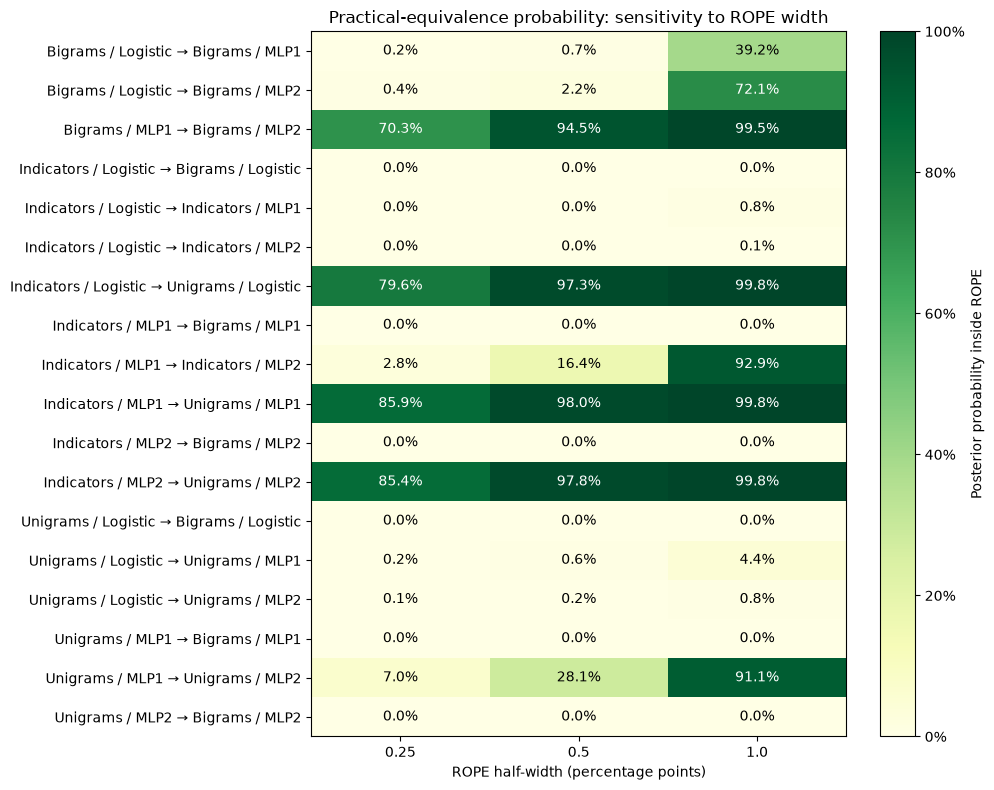

,figure
0,bayesian_posteriors_rope.png
1,cv_accuracy.png
2,cv_boxplots_and_points.png
3,rope_sensitivity.png
4,test_class_metrics.png
5,test_confusion.png
6,training_curves.png


In [21]:
equivalence = sensitivity.pivot(
    index=["A", "B"], columns="ROPE half-width (pp)", values="P_equivalent"
)
comparison_labels = [f"{system_name(tuple(a.split(' / ')))} → {system_name(tuple(b.split(' / ')))}"
                     for a, b in equivalence.index]
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(equivalence.to_numpy(), vmin=0, vmax=1, cmap="YlGn", aspect="auto")
for row in range(len(equivalence)):
    for column in range(len(equivalence.columns)):
        value = equivalence.iloc[row, column]
        ax.text(column, row, f"{value:.1%}", ha="center", va="center",
                color="white" if value > 0.65 else "black")
ax.set(xticks=range(len(equivalence.columns)), xticklabels=equivalence.columns,
       yticks=range(len(equivalence)), yticklabels=comparison_labels,
       xlabel="ROPE half-width (percentage points)",
       title="Practical-equivalence probability: sensitivity to ROPE width")
fig.colorbar(image, ax=ax, label="Posterior probability inside ROPE", format=PercentFormatter(1))
fig.tight_layout()
save_figure(fig, "rope_sensitivity")
plt.show()

display(pd.DataFrame({"figure": sorted(path.name for path in FIGURES.glob("*.png"))}))


### Reading these results

For this saved run, **indicators + MLP2 (128 → 64)** has the highest mean CV
accuracy, **62.60%**, and lowest CV NLL, **0.8394**. Unigram MLP2 is almost tied
at **62.59%**; their **97.75%** posterior probability inside the ±0.5 pp ROPE
supports practical equivalence under this analysis. The numerical winner is
selected by the fixed rule, without claiming that it is materially superior.

The full-pool refit achieves **74.48% official-test accuracy**, NLL **0.6210** and
macro-F1 **0.7439**. CV took **3.09 minutes** and final preparation/fitting
**51.54 seconds**. More labelled training data and different evaluation examples
make the CV and test scores different comparisons. The fixed three-epoch schedule
is not a claim of optimal training length.

The test errors include a choir's **church/baseball venue conflict** predicted
as entailment, an **unsupported age claim** (“The woman is young”) also predicted
as entailment, and a Land Rover **crossing/splashing-water inference** missed as
neutral. These suggest limits in contextual inference and sentence interactions;
they do not prove a single cause of the model's errors. Students should verify
the examples and label conventions. Full checked tables and limitations are in
[PROJECT1_FINDINGS.md](PROJECT1_FINDINGS.md).


## Sources and assistance

- [Project requirements](project.ipynb) and [course tutorial](tutorial.ipynb).
- [SNLI dataset](https://huggingface.co/datasets/stanfordnlp/snli), pinned above.
- [Course-method map](COURSE_METHODS.md), with lecture page references.
- Presentation reference: [NLP1 Practical 2](https://github.com/S-Chaudhuri/uva_nlp1_2025/blob/main/NLP1_2025_Practical_2_%28student%29.ipynb).
- [AI-assistance record](AI_ASSISTANCE.md). Implementation and initial interpretation
  were AI-assisted; group members must review, explain and validate the report.
